Bidirectional RNN MSE: 0.1793
Feed-Forward NN MSE: 0.2553


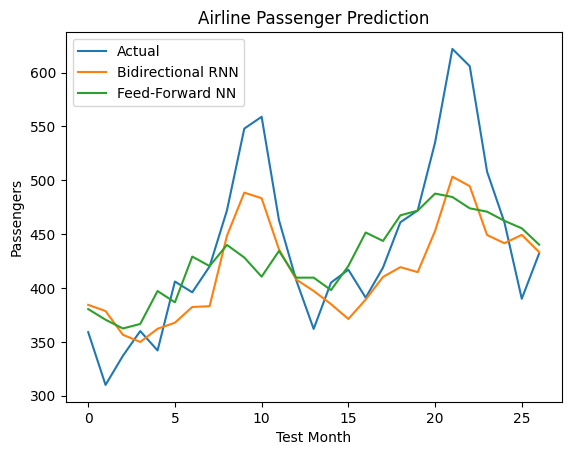

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
data = pd.read_csv(url)
values = data["Passengers"].values.astype("float32")

mean, std = values.mean(), values.std()
values = (values - mean) / std

X, y = [], []
for i in range(len(values) - 12):
    X.append(values[i:i+12])
    y.append(values[i+12])

X, y = np.array(X), np.array(y)
X = X.reshape(-1, 12, 1)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
rnn = models.Sequential([
            layers.Input(shape=(12, 1)),
                layers.Bidirectional(layers.SimpleRNN(16)),
                    layers.Dense(1)
                    ])

rnn.compile(optimizer="adam", loss="mse")
rnn.fit(X_train, y_train, epochs=30, verbose=0)

ffn = models.Sequential([
                        layers.Input(shape=(12,)),
                            layers.Dense(32, activation="relu"),
                                layers.Dense(16, activation="relu"),
                                    layers.Dense(1)
                                    ])

ffn.compile(optimizer="adam", loss="mse")
ffn.fit(X_train.reshape(-1, 12), y_train, epochs=30, verbose=0)
rnn_pred = rnn.predict(X_test, verbose=0).flatten()
ffn_pred = ffn.predict(X_test.reshape(-1, 12), verbose=0).flatten()
print("Bidirectional RNN MSE:", round(np.mean((y_test-rnn_pred)**2), 4))
print("Feed-Forward NN MSE:", round(np.mean((y_test-ffn_pred)**2), 4))
plt.plot(y_test * std + mean, label="Actual")
plt.plot(rnn_pred * std + mean, label="Bidirectional RNN")
plt.plot(ffn_pred * std + mean, label="Feed-Forward NN")
plt.xlabel("Test Month")
plt.ylabel("Passengers")
plt.title("Airline Passenger Prediction")
plt.legend()
plt.show()
